# Exploratory Data Analysis (EDA) Project
## 8. Multivariate Analysis

**Name:** ANINDO PRITOM BARUA  
**Registration Number:** 23BDS0328  
**Course:** Exploratory Data Analysis (EDA)  
**Dataset:** Indian Food Dataset

### Objective

The objective of this notebook is to perform multivariate analysis on the Indian Food dataset. Multivariate analysis examines three or more variables simultaneously to identify complex relationships and patterns within the data.

Different visualization techniques such as bubble plots, correlation heatmaps, pair plots, faceted scatter plots, parallel coordinate plots, and multivariable scatter plots will be used to analyze relationships among numerical and categorical variables.

MULTIVARIATE ANALYSIS

Dataset loaded successfully.
Rows    : 255
Columns : 20


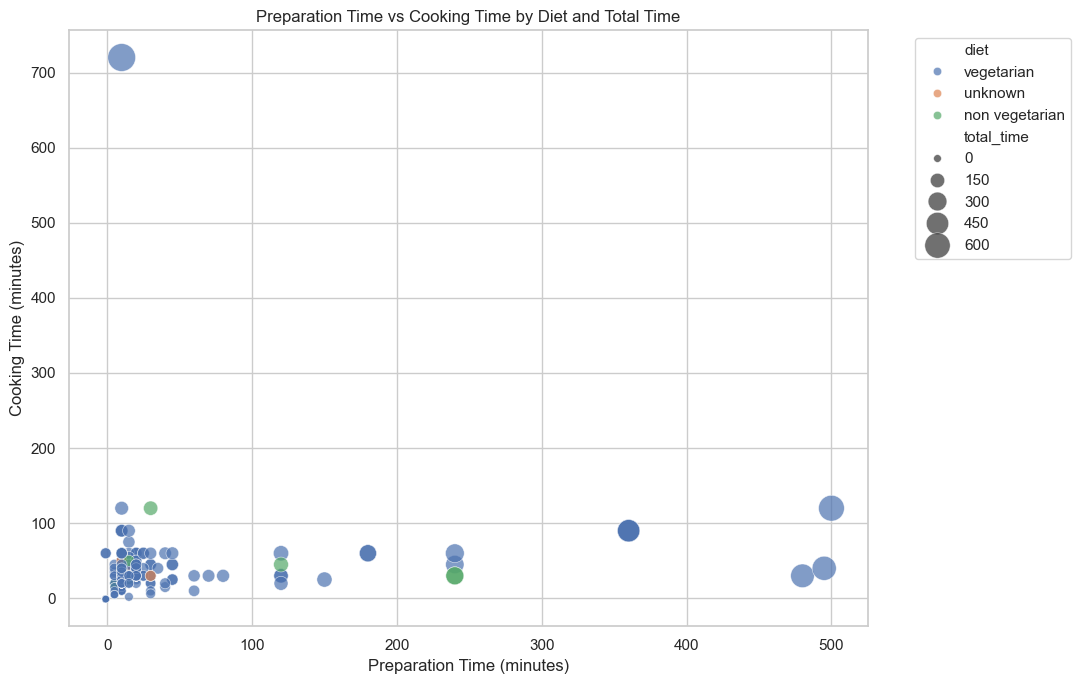

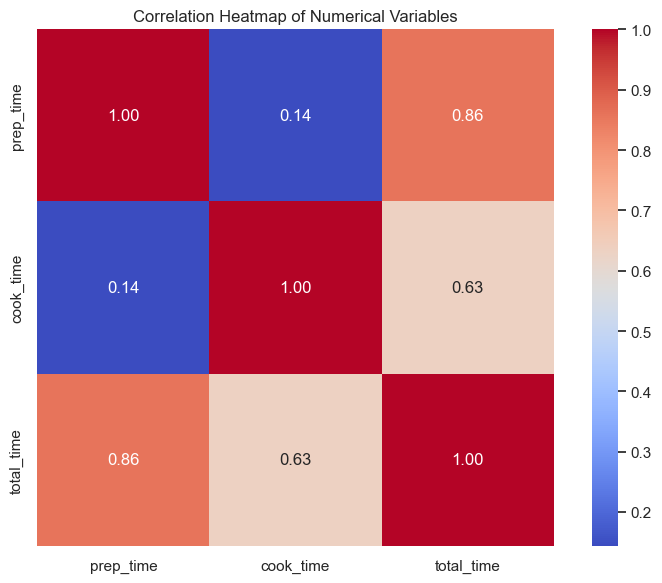

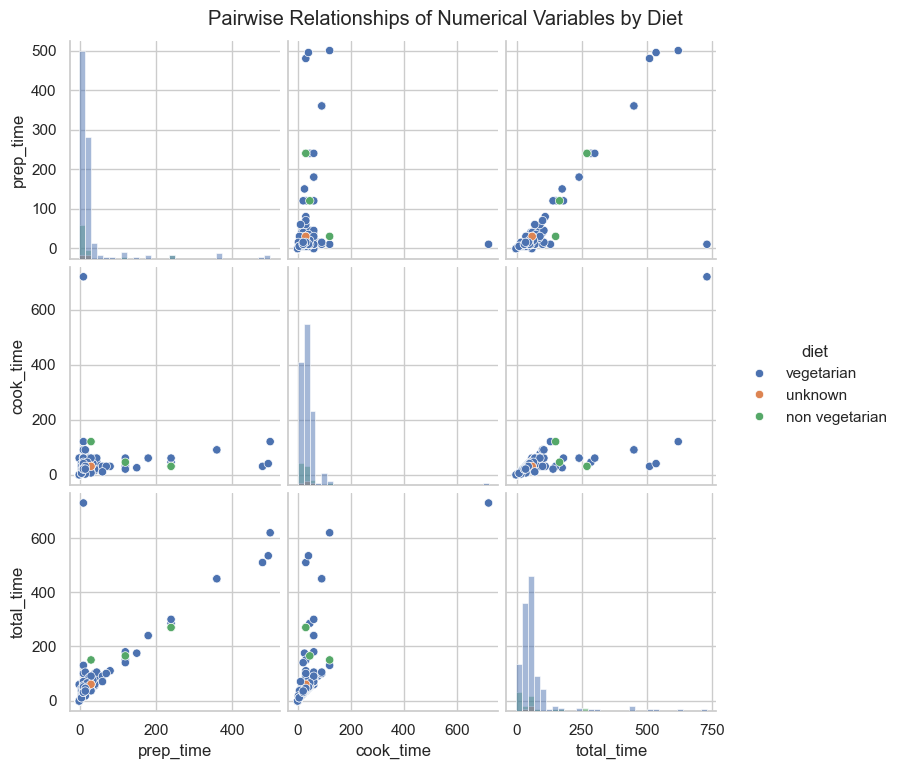

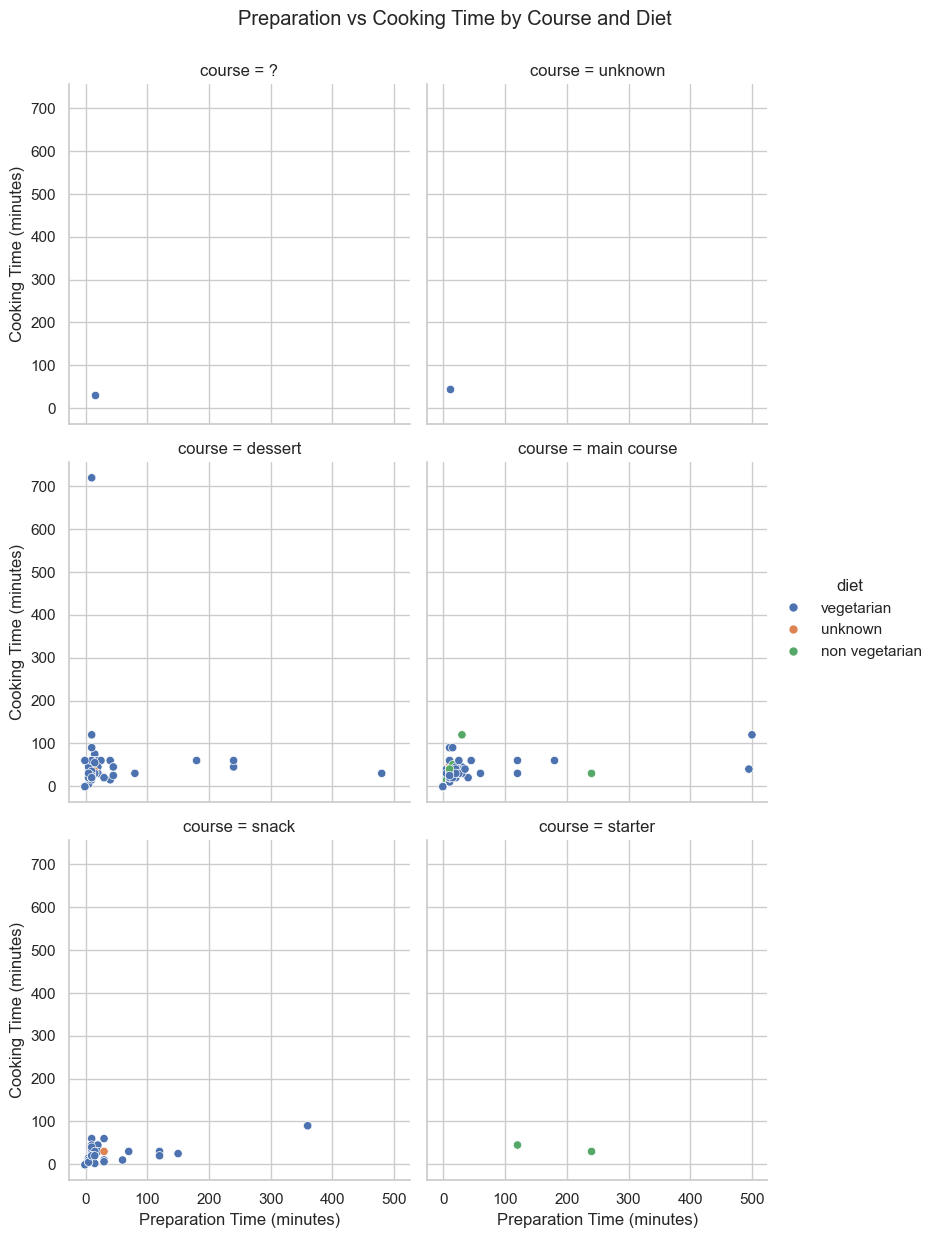

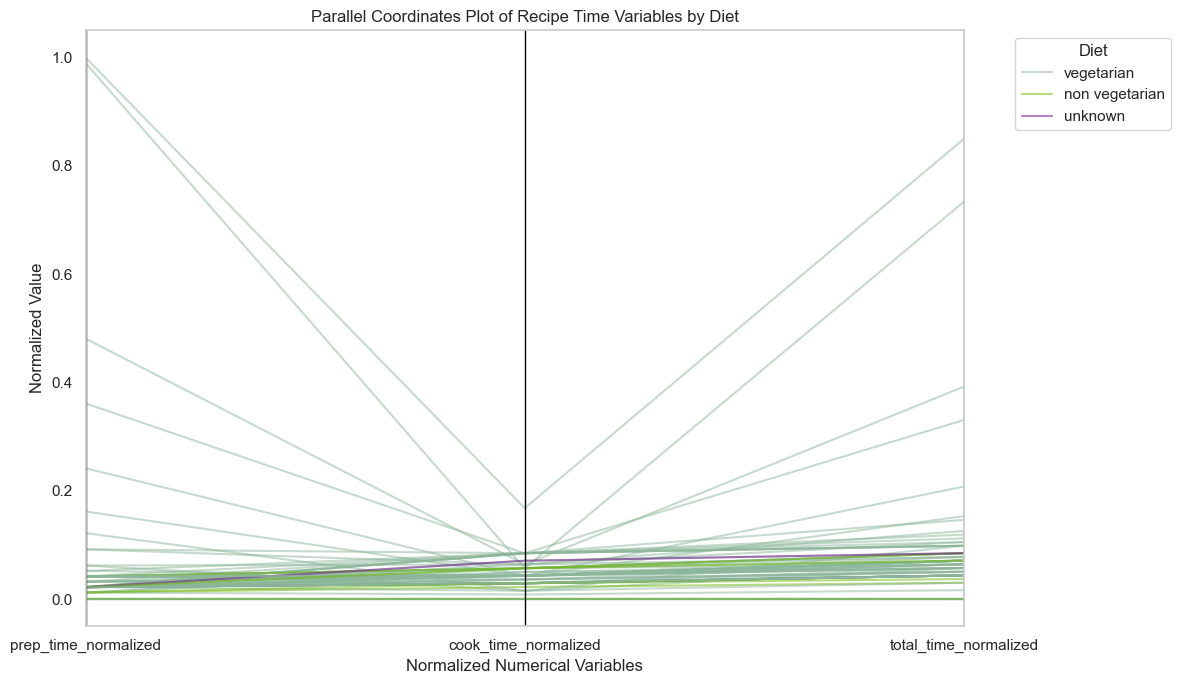

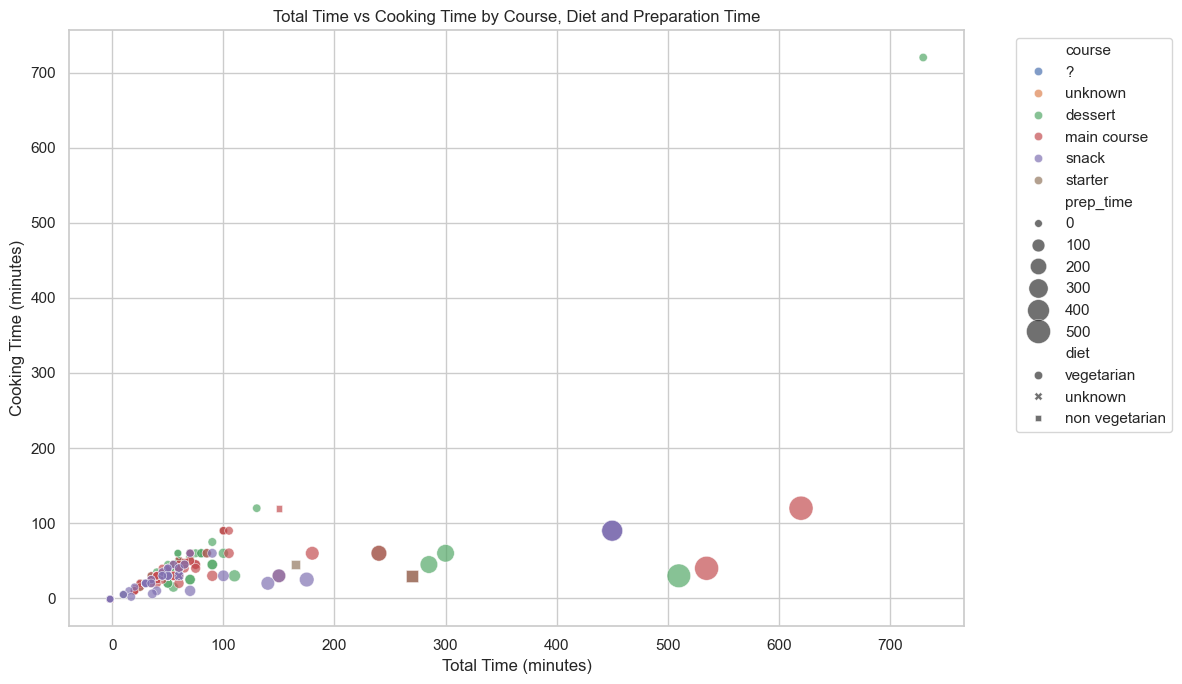


CORRELATION MATRIX


,prep_time,cook_time,total_time
prep_time,1.000000,0.144113,0.857228
cook_time,0.144113,1.000000,0.633100
total_time,0.857228,0.633100,1.000000



NUMERICAL SUMMARY GROUPED BY DIET


,prep_time,cook_time,total_time
diet,,,
non vegetarian,27.68,25.00,52.68
unknown,16.25,33.75,50.00
vegetarian,31.80,35.74,67.54



NUMERICAL SUMMARY GROUPED BY COURSE


,prep_time,cook_time,total_time
course,,,
?,15.00,30.00,45.00
dessert,27.40,44.08,71.48
main course,25.16,29.93,55.09
snack,51.97,29.10,81.08
starter,180.00,37.50,217.50
unknown,10.00,45.00,55.00



MULTIVARIATE ANALYSIS COMPLETED


In [1]:
# ============================================================
# EDA PROJECT - MULTIVARIATE ANALYSIS
# Name        : ANINDO PRITOM BARUA
# Registration: 23BDS0328
# Dataset     : Indian Food Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import parallel_coordinates

# ------------------------------------------------------------
# 1. Load the transformed dataset
# ------------------------------------------------------------

file_path = "indian_food_transformed.csv"

df = pd.read_csv(file_path)

print("=" * 70)
print("MULTIVARIATE ANALYSIS")
print("=" * 70)

print("\nDataset loaded successfully.")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

sns.set_theme(style="whitegrid")


# ------------------------------------------------------------
# 2. VISUALIZATION 1
# Bubble Plot:
# Preparation Time vs Cooking Time
# Bubble Size = Total Time
# Color = Diet
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="prep_time",
    y="cook_time",
    size="total_time",
    hue="diet",
    sizes=(30, 400),
    alpha=0.7
)

plt.title(
    "Preparation Time vs Cooking Time by Diet and Total Time"
)
plt.xlabel("Preparation Time (minutes)")
plt.ylabel("Cooking Time (minutes)")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. VISUALIZATION 2
# Correlation Heatmap
# ------------------------------------------------------------

numerical_data = df[
    [
        "prep_time",
        "cook_time",
        "total_time"
    ]
]

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. VISUALIZATION 3
# Pair Plot
# Numerical Variables + Diet
# ------------------------------------------------------------

pair_data = df[
    [
        "prep_time",
        "cook_time",
        "total_time",
        "diet"
    ]
].dropna()

sns.pairplot(
    pair_data,
    hue="diet",
    diag_kind="hist"
)

plt.suptitle(
    "Pairwise Relationships of Numerical Variables by Diet",
    y=1.02
)

plt.show()


# ------------------------------------------------------------
# 5. VISUALIZATION 4
# Faceted Scatter Plot
# Preparation Time vs Cooking Time
# Separated by Course
# Color = Diet
# ------------------------------------------------------------

facet_data = df[
    [
        "prep_time",
        "cook_time",
        "course",
        "diet"
    ]
].dropna()

g = sns.relplot(
    data=facet_data,
    x="prep_time",
    y="cook_time",
    hue="diet",
    col="course",
    col_wrap=2,
    kind="scatter",
    height=4
)

g.set_axis_labels(
    "Preparation Time (minutes)",
    "Cooking Time (minutes)"
)

g.fig.suptitle(
    "Preparation vs Cooking Time by Course and Diet",
    y=1.03
)

plt.show()


# ------------------------------------------------------------
# 6. VISUALIZATION 5
# Parallel Coordinates Plot
# ------------------------------------------------------------

parallel_data = df[
    [
        "prep_time_normalized",
        "cook_time_normalized",
        "total_time_normalized",
        "diet"
    ]
].dropna().copy()

# Use a sample to keep the graph readable
if len(parallel_data) > 80:
    parallel_data = parallel_data.sample(
        80,
        random_state=42
    )

plt.figure(figsize=(12, 7))

parallel_coordinates(
    parallel_data,
    class_column="diet",
    alpha=0.5
)

plt.title(
    "Parallel Coordinates Plot of Recipe Time Variables by Diet"
)
plt.xlabel("Normalized Numerical Variables")
plt.ylabel("Normalized Value")
plt.legend(
    title="Diet",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. VISUALIZATION 6
# Multivariable Scatter Plot
# X = Total Time
# Y = Cooking Time
# Color = Course
# Style = Diet
# Size = Preparation Time
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="total_time",
    y="cook_time",
    hue="course",
    style="diet",
    size="prep_time",
    sizes=(30, 300),
    alpha=0.7
)

plt.title(
    "Total Time vs Cooking Time by Course, Diet and Preparation Time"
)
plt.xlabel("Total Time (minutes)")
plt.ylabel("Cooking Time (minutes)")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Display Correlation Matrix
# ------------------------------------------------------------

print("\nCORRELATION MATRIX")
print("=" * 70)

display(correlation_matrix)


# ------------------------------------------------------------
# 9. Numerical Summary by Diet
# ------------------------------------------------------------

print("\nNUMERICAL SUMMARY GROUPED BY DIET")
print("=" * 70)

diet_summary = df.groupby("diet")[
    [
        "prep_time",
        "cook_time",
        "total_time"
    ]
].mean().round(2)

display(diet_summary)


# ------------------------------------------------------------
# 10. Numerical Summary by Course
# ------------------------------------------------------------

print("\nNUMERICAL SUMMARY GROUPED BY COURSE")
print("=" * 70)

course_summary = df.groupby("course")[
    [
        "prep_time",
        "cook_time",
        "total_time"
    ]
].mean().round(2)

display(course_summary)


# ------------------------------------------------------------
# 11. Completion
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MULTIVARIATE ANALYSIS COMPLETED")
print("=" * 70)

## Conclusion

Multivariate analysis was successfully performed on the Indian Food dataset to examine relationships among three or more variables simultaneously.

The bubble plot demonstrated the relationship between preparation time, cooking time, total time, and diet type. The correlation heatmap and pair plot were used to examine relationships among the numerical variables.

Faceted visualization allowed preparation and cooking times to be compared across different courses and diet types. The parallel coordinates plot provided a combined view of normalized time-related variables, while the multivariable scatter plot simultaneously represented total time, cooking time, preparation time, course, and diet.

The multivariate analysis provided a broader understanding of the interactions among the variables and completed the exploratory analysis of the Indian Food dataset.